In [1]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [4]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

# Load the saved XGBoost model
xgb_model = joblib.load("../models/xgboost_fraud_model.pkl")

# Load model metadata
model_metadata = joblib.load("../models/xgboost_metadata.pkl")

# Display the selected threshold
threshold = model_metadata["threshold"]

print("Model loaded successfully!")
print("Decision threshold:", threshold)

Model loaded successfully!
Decision threshold: 0.8


In [6]:
import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

# Load the trained model
xgb_model = joblib.load("../models/xgboost_fraud_model.pkl")

# Load model metadata
model_metadata = joblib.load("../models/xgboost_metadata.pkl")

# Load test features and labels
X_test = joblib.load("../data/processed/X_test.pkl")
y_test = joblib.load("../data/processed/y_test.pkl")

print("Model loaded successfully!")
print("Test data loaded successfully!")

print("Test features shape:", X_test.shape)
print("Test labels shape:", y_test.shape)

Model loaded successfully!
Test data loaded successfully!
Test features shape: (918617, 9)
Test labels shape: (918617,)


In [7]:
# Select a manageable sample of test transactions
X_shap = X_test.sample(
    n=1000,
    random_state=42
)

print("SHAP dataset shape:", X_shap.shape)

SHAP dataset shape: (1000, 9)


In [8]:
# Create a SHAP explainer for our XGBoost model
explainer = shap.TreeExplainer(xgb_model)

print("SHAP explainer created successfully!")

SHAP explainer created successfully!


In [9]:
# Calculate SHAP values for our sample transactions
shap_values = explainer(X_shap)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


In [10]:
print(shap_values)

.values =
array([[-1.9901097e+00, -3.6171677e+00, -8.2686782e-01, ...,
         7.3371170e-04,  1.5461314e-01, -2.4677028e-01],
       [-1.1844968e+00, -7.7198327e-01, -1.9457937e+00, ...,
         3.6233847e-03,  6.0389692e-01,  9.1242772e-01],
       [-2.2310255e+00, -3.2532289e+00, -4.5226965e+00, ...,
         9.7079307e-04,  2.2705090e-01, -1.8696553e-01],
       ...,
       [-1.9758723e+00, -3.3552549e+00, -2.0104170e+00, ...,
         5.3888100e-04,  1.4959735e-01, -1.9352993e-01],
       [-1.9846599e+00, -3.1727772e+00, -8.7132215e-01, ...,
         7.7005470e-04,  1.5501504e-01, -2.1951583e-01],
       [-1.5191708e+00, -2.5638955e+00, -3.1817791e+00, ...,
         1.0346186e-03, -2.8852975e+00, -6.1199623e-01]],
      shape=(1000, 9), dtype=float32)

.base_values =
array([0.8729592, 0.8729592, 0.8729592, 0.8729592, 0.8729592, 0.8729592,
       0.8729592, 0.8729592, 0.8729592, 0.8729592, 0.8729592, 0.8729592,
       0.8729592, 0.8729592, 0.8729592, 0.8729592, 0.8729592, 0.87295

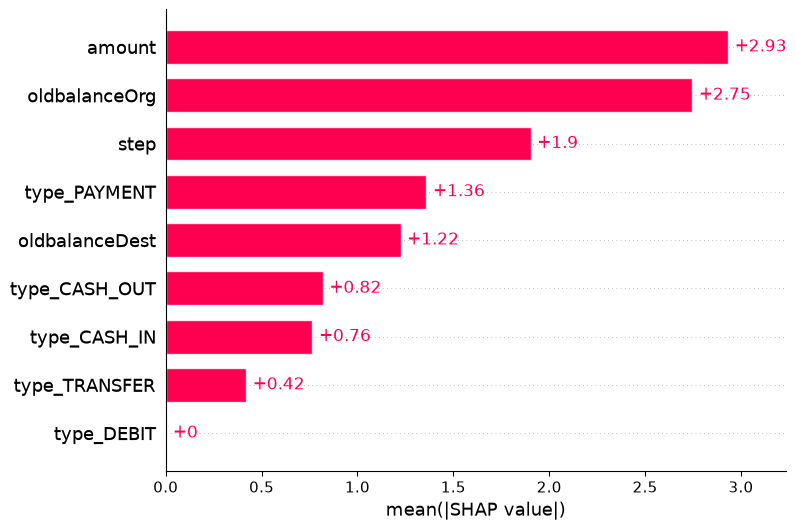

In [11]:
shap.plots.bar(shap_values, max_display=9)

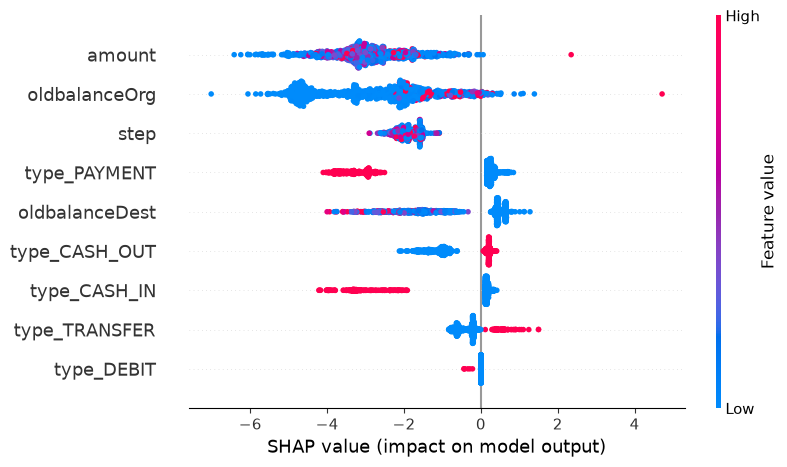

In [12]:
shap.plots.beeswarm(shap_values, max_display=9)

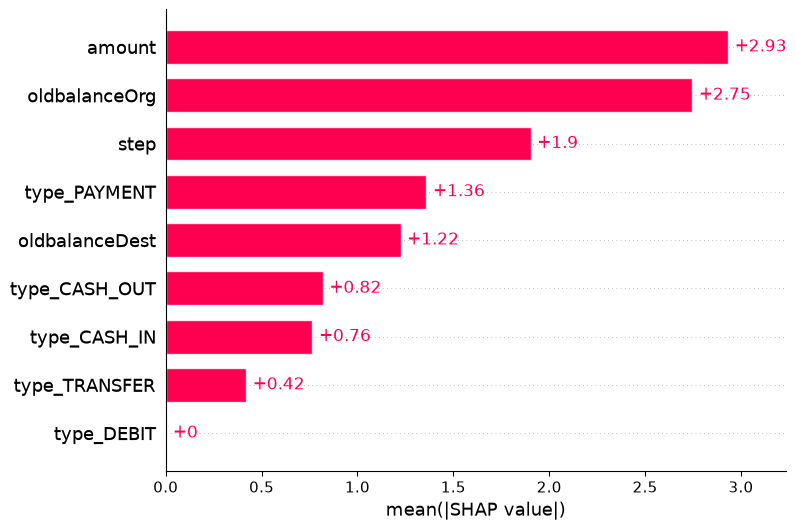

In [13]:
shap.plots.bar(shap_values, max_display=9)

In [14]:
# Find transactions that are actual fraud
# AND were predicted as suspicious by our model

threshold = model_metadata["threshold"]

test_probabilities = xgb_model.predict_proba(X_test)[:, 1]

true_positive_indices = np.where(
    (y_test.to_numpy() == 1) &
    (test_probabilities >= threshold)
)[0]

print("Number of correctly detected fraud transactions:", 
      len(true_positive_indices))

Number of correctly detected fraud transactions: 2718


In [15]:
# Select the first correctly detected fraud transaction
selected_index = true_positive_indices[0]

# Extract the transaction
single_transaction = X_test.iloc[[selected_index]]

# Get its actual fraud label
actual_label = y_test.iloc[selected_index]

# Get its predicted fraud score
fraud_score = test_probabilities[selected_index]

print("Transaction index:", selected_index)
print("Actual label:", actual_label)
print("Fraud score:", round(fraud_score, 4))
print("Prediction:", "Suspicious" if fraud_score >= threshold else "Legitimate")

display(single_transaction)

Transaction index: 10838
Actual label: 1
Fraud score: 0.9186
Prediction: Suspicious


,step,amount,oldbalanceOrg,oldbalanceDest,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
5454841,379,36942.13,36942.13,0.0,0,0,0,0,1


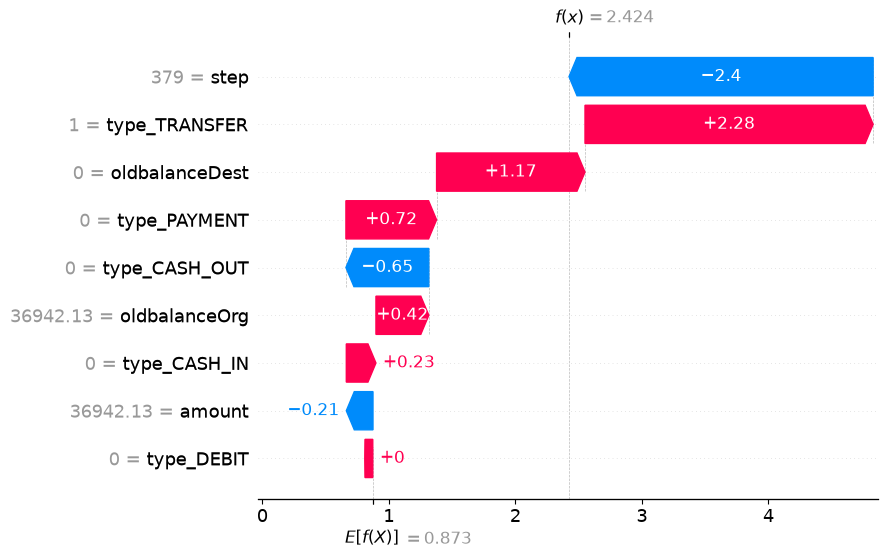

In [16]:
# Generate SHAP explanation for our selected transaction
single_shap = explainer(single_transaction)

# Display the explanation
shap.plots.waterfall(single_shap[0], max_display=9)